In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from keras.models import Sequential
from keras.layers import Dense, Dropout, BatchNormalization
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

### 2. User Config

In [10]:
# DATA & PARAMETERS
data_file_path = "NewData.xlsx"
input_coloumns = ["Dry Unit weight",  "Soil Type"]
output_coloumns = "Thaw Strain (%)"

continuous_features = ["Dry Unit weight","Thaw strain,%"]
categorical_features = ["Soil Type"]

# EXPORTING
export_results_to_excel_file = True
file_name = "results.xlsx"

# K FOLD
k_fold = 5

### 3. Data Preparation

*We assign the coloumns of our CSV into pandas database. The preprocess the data with the following:*

**One-Hot Encoding**: *We use One-Hot Encoding to represent soil type, a categorial data feature, into a unique binary columns. As such, each category for soil type (1, 2, 3) is represented as a seperate coloumn "Soil Type 1", "Soil Type 2", "Soil Type 3". This eliminates any false ordinality, preventing the model from interpreting “2” as somehow “between” or “greater than” “1” or “3.” In linear models, we typically drop one dummy to avoid multicollinearity.*

**Pressure Truncating**: *We removed any Pressure that is above 100 KPa.*

In [11]:
data_file = data_file_path
df_data = pd.read_excel(data_file)

# One Hot Encoding: Creating dummy coloumns for each of the categorical values of Soil Type, we drop the first one to avoid multicollinearity
df_data = df_data[df_data["Pressure,kpa"] <= 100]

"""
df_data = pd.get_dummies(df_data, columns=["Soil Type"],
                         prefix="soil",              
                         drop_first=True,            
                         dtype="int8")    

# Pressure: We drop the rows with pressure higher than 100 kpa


column_to_move = df_data.pop('soil_2')
column_to_move2 = df_data.pop('soil_3')
df_data.insert(2, 'soil_2', column_to_move)
df_data.insert(3, 'soil_3', column_to_move2)
df_data["soil_2"] = df_data["soil_2"].astype("category")
df_data["soil_3"] = df_data["soil_3"].astype("category")
"""

X = df_data.drop(columns=[output_coloumns, "Pressure,kpa"])
Y = df_data[output_coloumns]


print(X)
print(Y)

      Dry Unit Weight  Soil Type
0           11.933720          1
1           11.688030          1
2           11.622800          1
3           11.483480          1
4           11.195690          1
...               ...        ...
1494        14.244120          3
1500        13.292550          3
1513        12.952600          3
1529        13.680575          3
1553        13.754252          3

[1328 rows x 2 columns]
0        0.424000
1        5.638700
2        0.256000
3        6.246500
4       18.504100
          ...    
1494     0.410000
1500     0.340000
1513     3.241379
1529     7.500000
1553    10.533333
Name: Thaw Strain (%), Length: 1328, dtype: float64


In [ ]:
import optuna
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, make_scorer

# Assuming X and Y are already defined in your environment
# If not, you'll need to load your data here
# print(X.shape, Y.shape)  # Uncomment to check your data dimensions

def objective(trial):
    """Optuna objective function for GradientBoosting hyperparameter optimization"""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 1, 10),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'alpha': trial.suggest_float('alpha', 0.1, 0.9),  # Huber loss parameter
        'validation_fraction': trial.suggest_float('validation_fraction', 0.1, 0.3),
        'n_iter_no_change': trial.suggest_int('n_iter_no_change', 5, 20),
        'tol': trial.suggest_float('tol', 1e-5, 1e-3, log=True)
    }
    
    model = GradientBoostingRegressor(**params, random_state=42, criterion='friedman_mse')
    
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(
        model, X, Y, 
        scoring=make_scorer(mean_squared_error, greater_is_better=False),
        cv=cv
    )
    
    rmse = np.mean(np.sqrt(-scores))  # Convert negative MSE to positive RMSE
    return -rmse  # Return negative RMSE for minimization

# Create the study - note we use "minimize" since we want to minimize the negative RMSE
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=100)

# Print results
print("Best Parameters:", study.best_params)
print("Best RMSE:", -study.best_value)

In [ ]:
import xgboost as xgb
import numpy as np
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, make_scorer
import optuna

print(X)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.3),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 6),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'enable_categorical': True,
    }

    model = xgb.XGBRegressor(**params, random_state=42, verbosity=0)

    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(
        model, X, Y, 
        scoring=make_scorer(mean_squared_error, greater_is_better=False),
        cv=cv
    )

    rmse = np.mean(np.sqrt(-scores))  # Convert negative MSE to positive RMSE
    return -rmse  # Return negative RMSE for minimization

# Run the study
study = optuna.create_study(direction="maximize")  # We want to minimize RMSE
study.optimize(objective, n_trials=100)

print("Best Parameters:", study.best_params)
print("Best RMSE:", -study.best_value)  # Convert back to positive RMSE

In [ ]:
import optuna
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, make_scorer

# Assuming X and Y are already defined in your environment
# If not, you'll need to load your data here
# print(X.shape, Y.shape)  # Uncomment to check your data dimensions

def objective(trial):
    """Optuna objective function for RandomForest hyperparameter optimization"""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 250),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'bootstrap': trial.suggest_categorical('bootstrap', [True, False]),
    }
    
    model = RandomForestRegressor(**params, random_state=42, criterion='squared_error')
    
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(
        model, X, Y, 
        scoring=make_scorer(mean_squared_error, greater_is_better=False),
        cv=cv
    )
    
    rmse = np.mean(np.sqrt(-scores))  # Convert negative MSE to positive RMSE
    return -rmse  # Return negative RMSE for minimization

# Create the study - note we use "minimize" since we want to minimize the negative RMSE
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=100)

# Print results
print("Best Parameters:", study.best_params)
print("Best RMSE:", -study.best_value)

# Train a final model with the best parameters
best_params = study.best_params
best_model = RandomForestRegressor(**best_params, random_state=42, criterion='squared_error')
best_model.fit(X, Y)

# Optional: Feature importance
feature_importances = best_model.feature_importances_
if hasattr(X, 'columns'):  # If X is a pandas DataFrame
    for feature, importance in zip(X.columns, feature_importances):
        print(f"Feature: {feature}, Importance: {importance:.4f}")
else:
    # If X is a numpy array, just print feature indices
    for i, importance in enumerate(feature_importances):
        print(f"Feature {i}: Importance: {importance:.4f}")

In [ ]:
import numpy as np
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.preprocessing import StandardScaler
import optuna

def objective(trial):
    # SVR hyperparameters
    params = {
        'kernel': trial.suggest_categorical('kernel', ['rbf']),
        'C': trial.suggest_float('C', 0.1, 100.0, log=True),
        'epsilon': trial.suggest_float('epsilon', 0.01, 1.0),
        'shrinking': trial.suggest_categorical('shrinking', [True, False]),
        'tol': trial.suggest_float('tol', 1e-5, 1e-2, log=True),
    }
    
    # Handle gamma parameter correctly
    gamma_option = trial.suggest_categorical('gamma_option', ['scale', 'auto', 'value'])
    if gamma_option == 'value':
        params['gamma'] = trial.suggest_float('gamma_value', 0.001, 1.0, log=True)
    else:
        params['gamma'] = gamma_option  # Either 'scale' or 'auto'
    
    # Handle conditional parameters for polynomial kernel
    if params['kernel'] == 'poly':
        params['degree'] = trial.suggest_int('degree', 2, 5)

    # Create the SVR model
    model = SVR(**params)
    
    # We'll use a pipeline with StandardScaler since SVR is sensitive to feature scaling
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    
    # Scale the data first (you should implement this in your actual code)
    # For example: X_scaled = StandardScaler().fit_transform(X)
    # Then use X_scaled instead of X in cross_val_score
    
    # For this example, I'll assume X is already scaled or you'll scale it before using this function
    scores = cross_val_score(
        model, X, Y,  # Make sure X and y are defined in your actual code
        scoring=make_scorer(mean_squared_error, greater_is_better=False),
        cv=cv
    )

    rmse = np.mean(np.sqrt(-scores))  # Convert negative MSE to positive RMSE
    return rmse  # Return RMSE for minimization

# Add a suggestion for proper scaling
# In your actual implementation, you may want to use a pipeline:
'''
from sklearn.pipeline import Pipeline

def objective(trial):
    # SVR hyperparameters as defined above...
    
    # Create a pipeline with scaling
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('svr', SVR(**params))
    ])
    
    scores = cross_val_score(
        pipe, X, y,
        scoring=make_scorer(mean_squared_error, greater_is_better=False),
        cv=cv
    )
    
    rmse = np.mean(np.sqrt(-scores))
    return rmse
'''

# Run the study
study = optuna.create_study(direction="minimize")  # We want to minimize RMSE
study.optimize(objective, n_trials=100)

print("Best Parameters:", study.best_params)
print("Best RMSE:", study.best_value)

In [ ]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, make_scorer
import optuna

def objective(trial):
    # DecisionTreeRegressor hyperparameters
    params = {
        'criterion': trial.suggest_categorical('criterion', ['squared_error', 'friedman_mse', 'absolute_error', 'poisson']),
        'splitter': trial.suggest_categorical('splitter', ['best', 'random']),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20),
        'min_weight_fraction_leaf': trial.suggest_float('min_weight_fraction_leaf', 0.0, 0.5),
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']),
        'random_state': 42,
        'min_impurity_decrease': trial.suggest_float('min_impurity_decrease', 0.0, 0.2),
        'ccp_alpha': trial.suggest_float('ccp_alpha', 0.0, 0.1),
    }
    
    # Create the model
    model = DecisionTreeRegressor(**params)
    
    # Define cross-validation
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    
    scores = cross_val_score(
        model, X, Y,  # Make sure X and y are defined in your actual code
        scoring=make_scorer(mean_squared_error, greater_is_better=False),
        cv=cv
    )

    rmse = np.mean(np.sqrt(-scores))  # Convert negative MSE to positive RMSE
    return rmse  # Return RMSE for minimization

# Run the study
study = optuna.create_study(direction="minimize")  # We want to minimize RMSE
study.optimize(objective, n_trials=100)

print("Best Parameters:", study.best_params)
print("Best RMSE:", study.best_value)

# You can also print feature importance from the best model
best_params = study.best_params.copy()
if 'max_leaf_nodes_enabled' in best_params:
    if best_params['max_leaf_nodes_enabled']:
        best_params['max_leaf_nodes'] = best_params['max_leaf_nodes']
    else:
        best_params['max_leaf_nodes'] = None
    del best_params['max_leaf_nodes_enabled']

best_model = DecisionTreeRegressor(**best_params)
best_model.fit(X, Y)  # Assuming X and y are available in your code
print("\nFeature Importances:")
for i, importance in enumerate(best_model.feature_importances_):
    print(f"Feature {i}: {importance:.4f}")

In [12]:
import numpy as np
import optuna
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
from sklearn.base import clone

def nested_oof_knn_optuna(
    X, y, outer_splits=5, inner_splits=5, n_trials=100, random_state=42
):
    X = np.asarray(X)
    y = np.asarray(y).ravel()
    outer_cv = KFold(n_splits=outer_splits, shuffle=True, random_state=random_state)

    y_oof = np.empty_like(y, dtype=float)
    best_params_per_fold = []

    for outer_fold, (tr_idx, te_idx) in enumerate(outer_cv.split(X, y), start=1):
        X_tr, X_te = X[tr_idx], X[te_idx]
        y_tr, y_te = y[tr_idx], y[te_idx]

        inner_cv = KFold(n_splits=inner_splits, shuffle=True, random_state=random_state)

        def objective(trial):
            params = {
                "n_neighbors": trial.suggest_int("n_neighbors", 1, 400),
                "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
                "algorithm": trial.suggest_categorical("algorithm", ["auto","ball_tree","kd_tree","brute"]),
                "leaf_size": trial.suggest_int("leaf_size", 5, 1000),
                "p": trial.suggest_int("p", 1, 2),
            }
            pipe = Pipeline([
                ("scaler", StandardScaler()),
                ("knn", KNeighborsRegressor(**params))
            ])
            # Use neg RMSE so higher is better (Optuna "maximize")
            scores = cross_val_score(
                pipe, X_tr, y_tr,
                cv=inner_cv,
                scoring="neg_root_mean_squared_error",
                n_jobs=-1,
            )
            return scores.mean()

        study = optuna.create_study(direction="maximize")
        study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
        best_params = study.best_params
        best_params_per_fold.append(best_params)

        # Refit on full outer-train with best inner params
        final_pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsRegressor(**best_params))
        ])
        final_pipe.fit(X_tr, y_tr)
        y_oof[te_idx] = final_pipe.predict(X_te)

        rmse_fold = mean_squared_error(y_te, y_oof[te_idx], squared=False)
        print(f"[Outer {outer_fold}/{outer_splits}] RMSE={rmse_fold:.3f} | Best={best_params}")

    rmse = mean_squared_error(y, y_oof, squared=False)
    return y_oof, best_params_per_fold, rmse

y_oof, per_fold_params, cv_rmse = nested_oof_knn_optuna(X, Y, outer_splits=5, inner_splits=5, n_trials=200)
print("Nested-CV OOF RMSE:", cv_rmse)


[I 2025-09-15 16:29:23,970] A new study created in memory with name: no-name-3c129b21-42b0-481e-a98a-ea1e9aa9680d
[I 2025-09-15 16:29:27,087] Trial 0 finished with value: -6.977926698548491 and parameters: {'n_neighbors': 23, 'weights': 'distance', 'algorithm': 'kd_tree', 'leaf_size': 326, 'p': 2}. Best is trial 0 with value: -6.977926698548491.
[I 2025-09-15 16:29:28,602] Trial 1 finished with value: -7.171173200816068 and parameters: {'n_neighbors': 231, 'weights': 'distance', 'algorithm': 'brute', 'leaf_size': 120, 'p': 2}. Best is trial 0 with value: -6.977926698548491.
[I 2025-09-15 16:29:29,788] Trial 2 finished with value: -7.216738375749574 and parameters: {'n_neighbors': 255, 'weights': 'distance', 'algorithm': 'kd_tree', 'leaf_size': 345, 'p': 2}. Best is trial 0 with value: -6.977926698548491.
[I 2025-09-15 16:29:29,837] Trial 3 finished with value: -7.242759268500384 and parameters: {'n_neighbors': 268, 'weights': 'distance', 'algorithm': 'ball_tree', 'leaf_size': 601, 'p':

[Outer 1/5] RMSE=6.562 | Best={'n_neighbors': 55, 'weights': 'distance', 'algorithm': 'kd_tree', 'leaf_size': 428, 'p': 2}


[I 2025-09-15 16:29:47,273] Trial 4 finished with value: -7.6525369392514495 and parameters: {'n_neighbors': 319, 'weights': 'distance', 'algorithm': 'auto', 'leaf_size': 167, 'p': 1}. Best is trial 1 with value: -7.329476844156734.
[I 2025-09-15 16:29:47,387] Trial 5 finished with value: -13.564754062126084 and parameters: {'n_neighbors': 363, 'weights': 'uniform', 'algorithm': 'auto', 'leaf_size': 622, 'p': 1}. Best is trial 1 with value: -7.329476844156734.
[I 2025-09-15 16:29:47,500] Trial 6 finished with value: -12.68471254247418 and parameters: {'n_neighbors': 236, 'weights': 'uniform', 'algorithm': 'brute', 'leaf_size': 289, 'p': 1}. Best is trial 1 with value: -7.329476844156734.
[I 2025-09-15 16:29:47,532] Trial 7 finished with value: -7.262753397977724 and parameters: {'n_neighbors': 35, 'weights': 'distance', 'algorithm': 'brute', 'leaf_size': 869, 'p': 2}. Best is trial 7 with value: -7.262753397977724.
[I 2025-09-15 16:29:47,573] Trial 8 finished with value: -10.6888585729

[Outer 2/5] RMSE=6.704 | Best={'n_neighbors': 62, 'weights': 'distance', 'algorithm': 'kd_tree', 'leaf_size': 748, 'p': 2}


[I 2025-09-15 16:30:06,850] Trial 3 finished with value: -7.499488884280583 and parameters: {'n_neighbors': 311, 'weights': 'distance', 'algorithm': 'brute', 'leaf_size': 290, 'p': 2}. Best is trial 2 with value: -7.421343276447132.
[I 2025-09-15 16:30:06,906] Trial 4 finished with value: -13.393082574554512 and parameters: {'n_neighbors': 283, 'weights': 'uniform', 'algorithm': 'ball_tree', 'leaf_size': 576, 'p': 1}. Best is trial 2 with value: -7.421343276447132.
[I 2025-09-15 16:30:06,955] Trial 5 finished with value: -13.390746592028819 and parameters: {'n_neighbors': 381, 'weights': 'uniform', 'algorithm': 'ball_tree', 'leaf_size': 928, 'p': 2}. Best is trial 2 with value: -7.421343276447132.
[I 2025-09-15 16:30:07,004] Trial 6 finished with value: -10.522591108929259 and parameters: {'n_neighbors': 94, 'weights': 'uniform', 'algorithm': 'kd_tree', 'leaf_size': 227, 'p': 2}. Best is trial 2 with value: -7.421343276447132.
[I 2025-09-15 16:30:07,054] Trial 7 finished with value: -7

[Outer 3/5] RMSE=7.063 | Best={'n_neighbors': 52, 'weights': 'distance', 'algorithm': 'ball_tree', 'leaf_size': 297, 'p': 1}


[I 2025-09-15 16:30:25,905] Trial 1 finished with value: -6.977620045308465 and parameters: {'n_neighbors': 320, 'weights': 'distance', 'algorithm': 'brute', 'leaf_size': 606, 'p': 2}. Best is trial 0 with value: -6.878131647173326.
[I 2025-09-15 16:30:25,972] Trial 2 finished with value: -12.039230393162807 and parameters: {'n_neighbors': 170, 'weights': 'uniform', 'algorithm': 'auto', 'leaf_size': 11, 'p': 1}. Best is trial 0 with value: -6.878131647173326.
[I 2025-09-15 16:30:26,054] Trial 3 finished with value: -6.785380911007506 and parameters: {'n_neighbors': 196, 'weights': 'distance', 'algorithm': 'brute', 'leaf_size': 753, 'p': 2}. Best is trial 3 with value: -6.785380911007506.
[I 2025-09-15 16:30:26,104] Trial 4 finished with value: -11.308723171018395 and parameters: {'n_neighbors': 145, 'weights': 'uniform', 'algorithm': 'ball_tree', 'leaf_size': 195, 'p': 2}. Best is trial 3 with value: -6.785380911007506.
[I 2025-09-15 16:30:26,169] Trial 5 finished with value: -7.042158

[Outer 4/5] RMSE=6.848 | Best={'n_neighbors': 76, 'weights': 'distance', 'algorithm': 'brute', 'leaf_size': 350, 'p': 2}


[I 2025-09-15 16:30:42,189] Trial 4 finished with value: -12.209855755933033 and parameters: {'n_neighbors': 178, 'weights': 'uniform', 'algorithm': 'auto', 'leaf_size': 678, 'p': 1}. Best is trial 3 with value: -7.372745011146316.
[I 2025-09-15 16:30:42,284] Trial 5 finished with value: -7.566964873122261 and parameters: {'n_neighbors': 268, 'weights': 'distance', 'algorithm': 'ball_tree', 'leaf_size': 140, 'p': 2}. Best is trial 3 with value: -7.372745011146316.
[I 2025-09-15 16:30:42,350] Trial 6 finished with value: -7.405862810325201 and parameters: {'n_neighbors': 128, 'weights': 'distance', 'algorithm': 'auto', 'leaf_size': 366, 'p': 2}. Best is trial 3 with value: -7.372745011146316.
[I 2025-09-15 16:30:42,430] Trial 7 finished with value: -11.306321759013397 and parameters: {'n_neighbors': 128, 'weights': 'uniform', 'algorithm': 'auto', 'leaf_size': 522, 'p': 2}. Best is trial 3 with value: -7.372745011146316.
[I 2025-09-15 16:30:42,495] Trial 8 finished with value: -7.3779864

[Outer 5/5] RMSE=6.779 | Best={'n_neighbors': 70, 'weights': 'distance', 'algorithm': 'auto', 'leaf_size': 447, 'p': 1}
Nested-CV OOF RMSE: 6.793285427589455


In [30]:
import optuna
import numpy as np
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.preprocessing import StandardScaler

print(X, Y)

def objective(trial):
    """Optuna objective function for KNN hyperparameter optimization"""
    params = {
        'n_neighbors': trial.suggest_int('n_neighbors', 1, 400),
        'weights': trial.suggest_categorical('weights', ['uniform', 'distance']),
        'algorithm': trial.suggest_categorical('algorithm', ['auto', 'ball_tree', 'kd_tree', 'brute']),
        'leaf_size': trial.suggest_int('leaf_size', 5, 1000),
        'p': trial.suggest_int('p', 1, 2),  # p=1 for manhattan_distance, p=2 for euclidean_distance
    }
    
    # KNN is sensitive to feature scaling, so we'll use StandardScaler
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    model = KNeighborsRegressor(**params)
    
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(
        model, X_scaled, Y, 
        scoring=make_scorer(mean_squared_error, greater_is_better=False),
        cv=cv
    )
    
    rmse = np.mean(np.sqrt(-scores))  # Convert negative MSE to positive RMSE
    return -rmse  # Return negative RMSE for minimization

# Create the study - note we use "minimize" since we want to minimize the negative RMSE
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=200)

# Print results
print("Best Parameters:", study.best_params)
print("Best RMSE:", -study.best_value)


[I 2025-09-05 02:05:40,312] A new study created in memory with name: no-name-b3e2bf61-1f35-4a22-9d59-1c5518296f89
[I 2025-09-05 02:05:40,371] Trial 0 finished with value: -6.83535598323202 and parameters: {'n_neighbors': 176, 'weights': 'distance', 'algorithm': 'auto', 'leaf_size': 135, 'p': 1}. Best is trial 0 with value: -6.83535598323202.
[I 2025-09-05 02:05:40,414] Trial 1 finished with value: -6.770865288608616 and parameters: {'n_neighbors': 68, 'weights': 'distance', 'algorithm': 'auto', 'leaf_size': 751, 'p': 2}. Best is trial 1 with value: -6.770865288608616.


      Dry Unit weight  Soil Type
0           11.933720          1
1           11.688030          1
2           11.622800          1
3           11.483480          1
4           11.195690          1
...               ...        ...
1494        14.244120          3
1500        13.292550          3
1513        12.952600          3
1529        13.680575          3
1553        13.754252          3

[1328 rows x 2 columns] 0        0.424000
1        5.638700
2        0.256000
3        6.246500
4       18.504100
          ...    
1494     0.410000
1500     0.340000
1513     3.241379
1529     7.500000
1553    10.533333
Name: Thaw strain,%, Length: 1328, dtype: float64


[I 2025-09-05 02:05:40,661] Trial 2 finished with value: -7.020154910583993 and parameters: {'n_neighbors': 399, 'weights': 'distance', 'algorithm': 'brute', 'leaf_size': 375, 'p': 2}. Best is trial 1 with value: -6.770865288608616.
[I 2025-09-05 02:05:40,875] Trial 3 finished with value: -6.998538198421278 and parameters: {'n_neighbors': 353, 'weights': 'distance', 'algorithm': 'brute', 'leaf_size': 468, 'p': 1}. Best is trial 1 with value: -6.770865288608616.
[I 2025-09-05 02:05:41,057] Trial 4 finished with value: -6.846184219850102 and parameters: {'n_neighbors': 191, 'weights': 'distance', 'algorithm': 'brute', 'leaf_size': 958, 'p': 1}. Best is trial 1 with value: -6.770865288608616.
[I 2025-09-05 02:05:41,113] Trial 5 finished with value: -13.272514769131309 and parameters: {'n_neighbors': 340, 'weights': 'uniform', 'algorithm': 'auto', 'leaf_size': 983, 'p': 1}. Best is trial 1 with value: -6.770865288608616.
[I 2025-09-05 02:05:41,151] Trial 6 finished with value: -6.822054852

Best Parameters: {'n_neighbors': 94, 'weights': 'distance', 'algorithm': 'brute', 'leaf_size': 253, 'p': 2}
Best RMSE: 6.762486433252273


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from tensorflow import keras
import keras_tuner as kt

# --- 1) Prepare your data ---
# Assume you already have X (DataFrame) and Y (Series or array)
# For example:
# df = pd.read_csv("your_data.csv")
# X = df.drop("target", axis=1)
# Y = df["target"]

# Split into train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# --- 2) Define a model‐building function for the tuner ---
def build_model(hp):
    model = keras.Sequential()
    # Input layer
    model.add(keras.layers.Input(shape=(X_train.shape[1],)))
    
    # Tune the number of hidden layers and units
    for i in range(hp.Int("num_layers", 1, 10)):
        model.add(
            keras.layers.Dense(
                units=hp.Int(f"units_{i}", min_value=16, max_value=256, step=16),
                activation=hp.Choice("activation", ["relu", "linear"])
            )
        )
        # Optional dropout
        if hp.Boolean(f"dropout_{i}"):
            model.add(keras.layers.Dropout(rate=hp.Float(f"dropout_rate_{i}", 0.1, 0.5, step=0.1)))
    
    # Output layer for regression
    model.add(keras.layers.Dense(1, activation="linear"))
    
    # Compile
    model.compile(
        optimizer=keras.optimizers.Adam(
            hp.Float("learning_rate", 1e-4, 1e-2, sampling="log")
        ),
        loss="mse",
        metrics=[]
    )
    return model

# --- 3) Set up the tuner ---
tuner = kt.Hyperband(
    build_model,
    objective=kt.Objective("loss", direction="min"),
    max_epochs=50,
    factor=3,
    directory="kt_dir",
    project_name="bpnn_regression"
)

# Early stopping callback to prevent overfitting
stop_early = keras.callbacks.EarlyStopping(monitor="loss", patience=5)

# --- 4) Run the hyperparameter search ---
tuner.search(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    callbacks=[stop_early],
    verbose=1
)

# --- 5) Retrieve the best model and evaluate ---
best_model = tuner.get_best_models(num_models=1)[0]

# Fit it on the *entire* training data for a few more epochs if desired
best_model.fit(X_train, y_train, epochs=50, callbacks=[stop_early], verbose=0)

# Predict on test set
y_pred = best_model.predict(X_test).flatten()
best_model.summary()

# Compute RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Test RMSE: {rmse:.4f}")


In [28]:
import pandas as pd
import lightgbm as lgb
import optuna
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import numpy as np

# ====================
# LOAD DATA
# ====================


# ====================
# OPTUNA OBJECTIVE FUNCTION
# ====================
def objective(trial):
    # LightGBM hyperparameters to tune
    param = {
        "objective": "regression",
        "metric": "rmse",
        "boosting_type": "gbdt",
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "max_depth": trial.suggest_int("max_depth", 3, 15),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 2000),
    }

    # K-Fold CV
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_scores = []

    for train_idx, valid_idx in kf.split(X, Y):
        X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
        y_train, y_valid = Y.iloc[train_idx], Y.iloc[valid_idx]

        model = lgb.LGBMRegressor(**param)
        model.fit(
            X_train, y_train,
            eval_set=[(X_valid, y_valid)],
            eval_metric="rmse",
            categorical_feature=["Soil Type"]   # <-- KEY: treat Soil Type as categorical
        )

        preds = model.predict(X_valid)
        rmse = mean_squared_error(y_valid, preds, squared=False)
        rmse_scores.append(rmse)

    return np.mean(rmse_scores)

# ====================
# RUN OPTUNA
# ====================
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)  # Increase n_trials for better tuning

print("Best RMSE:", study.best_value)
print("Best Params:", study.best_params)

# ====================
# TRAIN FINAL MODEL WITH BEST PARAMS
# ====================
best_model = lgb.LGBMRegressor(**study.best_params)
best_model.fit(X, Y, categorical_feature=["Soil Type"])

# Save results to Excel
pd.DataFrame([{
    "Best RMSE": study.best_value,
    **study.best_params
}]).to_excel("results.xlsx", index=False)


ModuleNotFoundError: No module named 'lightgbm'

In [26]:
import pandas as pd
import numpy as np

from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, KFold

# === load & prep ===


# === define base learners ===
knn = KNeighborsRegressor(
    n_neighbors= 66, 
    weights= 'distance', 
    algorithm='kd_tree', 
    leaf_size = 99, 
    p= 2
)

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

# === stacking regressor ===
estimators = [
    ("knn", knn),
    ("rf", rf),
]

stack = StackingRegressor(
    estimators=estimators,
    final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 7)),
    cv=5,
    n_jobs=-1,
    passthrough=False     # only meta gets base predictions
)

# wrap in a pipeline if you want scaling (esp. for KNN)
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("stack", stack),
])

# === evaluate with 5-fold CV ===
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# note: cross_val_score on neg_mean_squared_error → RMSE
neg_mses = cross_val_score(pipeline, X, Y,
                           scoring="neg_mean_squared_error",
                           cv=kf, n_jobs=-1)
r2s      = cross_val_score(pipeline, X, Y,
                           scoring="r2",
                           cv=kf, n_jobs=-1)

rmse_scores = np.sqrt(-neg_mses)

print(f"Stacked RMSE: {rmse_scores.mean():.3f} ± {rmse_scores.std():.3f}")
print(f"Stacked R²: {r2s.mean():.3f} ± {r2s.std():.3f}")

# === finally, fit on full data ===
pipeline.fit(X, Y)


Stacked RMSE: 7.097 ± 0.250
Stacked R²: 0.841 ± 0.011


Pipeline(steps=[('scaler', StandardScaler()),
                ('stack',
                 StackingRegressor(cv=5,
                                   estimators=[('knn',
                                                KNeighborsRegressor(algorithm='kd_tree',
                                                                    leaf_size=99,
                                                                    n_neighbors=66,
                                                                    weights='distance')),
                                               ('rf',
                                                RandomForestRegressor(max_depth=10,
                                                                      n_estimators=200,
                                                                      random_state=42))],
                                   final_estimator=RidgeCV(alphas=array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03])),
                                   n_jobs=-1))])

      Dry Unit weight  Soil_1  Soil_2  Soil_3
0           11.933720    True   False   False
1           11.688030    True   False   False
2           11.622800    True   False   False
3           11.483480    True   False   False
4           11.195690    True   False   False
...               ...     ...     ...     ...
1494        14.244120   False   False    True
1500        13.292550   False   False    True
1513        12.952600   False   False    True
1529        13.680575   False   False    True
1553        13.754252   False   False    True

[1328 rows x 4 columns]
0        0.424000
1        5.638700
2        0.256000
3        6.246500
4       18.504100
          ...    
1494     0.410000
1500     0.340000
1513     3.241379
1529     7.500000
1553    10.533333
Name: Thaw strain,%, Length: 1328, dtype: float64
CV comparison:
    Model  RMSE Mean  RMSE Std   R2 Mean    R2 Std
0     KNN   6.759063  0.166015  0.855002  0.015354
1      RF   7.643888  0.339610  0.813268  0.031584
2     G

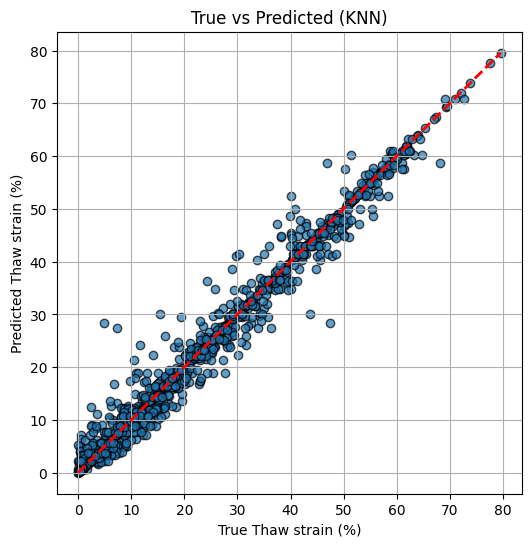

In [27]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error


print(X)
print(Y)

# 2. DEFINE A SUITE OF REGRESSORS
models = {
    "Linear":    LinearRegression(),
    "Ridge":     Ridge(alpha=1.0),
    "Lasso":     Lasso(alpha=0.1),
    "KNN":       KNeighborsRegressor(
                    n_neighbors=195, weights="distance",
                    algorithm="brute", p=1
                 ),
    "RF":        RandomForestRegressor(
                    n_estimators=200, max_depth=10, random_state=42
                 ),
    "GBR":       GradientBoostingRegressor(
                    n_estimators=500, learning_rate=0.05, random_state=42
                 ),
    "SVR":       SVR(kernel="rbf", C=1.0, epsilon=0.1)
}

# 3. CROSS-VALIDATE RMSE & R²
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    neg_mse = cross_val_score(
        model, X, Y,
        scoring="neg_mean_squared_error",
        cv=kf, n_jobs=-1
    )
    r2 = cross_val_score(
        model, X, Y,
        scoring="r2",
        cv=kf, n_jobs=-1
    )
    rmse = np.sqrt(-neg_mse)
    results.append({
        "Model":     name,
        "RMSE Mean": rmse.mean(),
        "RMSE Std":  rmse.std(),
        "R2 Mean":   r2.mean(),
        "R2 Std":    r2.std()
    })

results_df = pd.DataFrame(results).sort_values("RMSE Mean").reset_index(drop=True)

print("CV comparison:")
print(results_df)

# 4. PICK THE BEST & DISPLAY
best_model_name = results_df.loc[0, "Model"]
print(f"\nBest model by RMSE: {best_model_name}")

# 5. FIT THE FINAL MODEL ON ALL DATA
final_model = models[best_model_name]
final_model.fit(X, Y)
print(f"Trained `{best_model_name}` on the full dataset.")

import matplotlib.pyplot as plt

# 6. PREDICT AND PLOT TRUE vs PREDICTED
y_pred = final_model.predict(X)

plt.figure(figsize=(6, 6))
plt.scatter(Y, y_pred, alpha=0.7, edgecolors="k")
plt.plot([Y.min(), Y.max()], [Y.min(), Y.max()], "r--", lw=2)  # 1:1 line
plt.xlabel("True Thaw strain (%)")
plt.ylabel("Predicted Thaw strain (%)")
plt.title(f"True vs Predicted ({best_model_name})")
plt.grid(True)
plt.show()



In [32]:
import optuna
from sklearn.model_selection import cross_val_score, KFold
from catboost import CatBoostRegressor, Pool
import numpy as np

# categorical columns (soil type in your case)
cat_cols = ["Soil Type"]

def objective(trial):
    # Suggest hyperparameters
    params = {
        "iterations": 5000,
        "depth": trial.suggest_int("depth", 4, 10),
        "learning_rate": trial.suggest_loguniform("learning_rate", 1e-3, 0.3),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 10),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 10),
        "random_strength": trial.suggest_float("random_strength", 1e-9, 10),
        "border_count": trial.suggest_int("border_count", 32, 255),
        "loss_function": "RMSE",
        "eval_metric": "RMSE",
        "task_type": "CPU",   # or "GPU" if you have one
        "od_type": "Iter",
        "od_wait": 200,
        "verbose": False,
        "random_seed": 42,
    }

    # Cross-validation
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_scores = []

    for train_idx, valid_idx in kf.split(X):
        X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
        y_train, y_valid = Y.iloc[train_idx], Y.iloc[valid_idx]

        train_pool = Pool(X_train, y_train, cat_features=cat_cols)
        valid_pool = Pool(X_valid, y_valid, cat_features=cat_cols)

        model = CatBoostRegressor(**params)
        model.fit(train_pool, eval_set=valid_pool, use_best_model=True)

        preds = model.predict(X_valid)
        rmse = np.sqrt(((y_valid - preds) ** 2).mean())
        rmse_scores.append(rmse)

    return np.mean(rmse_scores)


# Run Optuna search
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)  # increase to 200+ for stronger search

print("Best RMSE:", study.best_value)
print("Best params:", study.best_params)



[I 2025-09-05 02:07:30,565] A new study created in memory with name: no-name-e61d3465-50c6-4263-b6c1-4da73794a374
C:\Users\dutta\AppData\Local\Temp\ipykernel_12100\672312109.py:14: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  "learning_rate": trial.suggest_loguniform("learning_rate", 1e-3, 0.3),
[W 2025-09-05 02:14:48,826] Trial 0 failed with parameters: {'depth': 4, 'learning_rate': 0.0029029144044601164, 'l2_leaf_reg': 6.608561770868111, 'bagging_temperature': 2.629416443310718, 'random_strength': 5.325465602030573, 'border_count': 230} because of the following error: KeyboardInterrupt('').
Traceback (most recent call last):
  File "c:\Users\dutta\miniconda3\envs\py38\lib\site-packages\optuna\study\_optimize.py", line 201, in _run_trial
    value_or_values = func(trial)
  File "C:\Users\dutta\AppData\Local\Temp\ipykernel_121

KeyboardInterrupt: 

In [34]:
# install autogluon if not already installed
# !pip install autogluon

from autogluon.tabular import TabularPredictor
import pandas as pd

# ---------- Load your dataset ----------
# df = pd.read_csv("your_data.csv")

# Split into train/test (you can also use KFold CV if you prefer)
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# ---------- Train AutoGluon ----------
predictor = TabularPredictor(
    label="Thaw strain,%",
    eval_metric="rmse"
).fit(
    train_data=train_df,
    presets="best_quality",     # strong models (slower, but better accuracy)
    time_limit=3600             # seconds, set higher if you want more tuning
)

# ---------- Check results ----------
leaderboard = predictor.leaderboard(test_df, silent=True)
print(leaderboard)

# ---------- Make predictions ----------
y_pred = predictor.predict(test_df.drop(columns=["Thaw strain,%"]))

# ---------- Evaluate performance ----------
perf = predictor.evaluate(test_df)
print("Final test performance:", perf)


No path specified. Models will be saved in: "AutogluonModels\ag-20250905_102039"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.8.20
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26100
CPU Count:          24
Memory Avail:       16.29 GB / 31.43 GB (51.8%)
Disk Space Avail:   836.97 GB / 951.65 GB (87.9%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdo

KeyboardInterrupt: 

In [36]:
from catboost import CatBoostRegressor, Pool
cat = CatBoostRegressor(
    depth=8, learning_rate=0.05, loss_function='RMSE',
    iterations=5000, od_type='Iter', od_wait=200, l2_leaf_reg=6,
    random_seed=42, eval_metric='RMSE'
)

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,        # 20% test set
    random_state=42,      # reproducibility
    shuffle=True
)
cat.fit(X_train, y_train,
        cat_features=cat_cols, verbose=200)


0:	learn: 17.1349329	total: 36.9ms	remaining: 3m 4s
200:	learn: 8.6389054	total: 6.78s	remaining: 2m 41s
400:	learn: 7.7163281	total: 15.6s	remaining: 2m 58s
600:	learn: 6.9984203	total: 24.3s	remaining: 2m 57s
800:	learn: 6.4708388	total: 32.9s	remaining: 2m 52s
1000:	learn: 6.0729767	total: 41.7s	remaining: 2m 46s
1200:	learn: 5.7579815	total: 50.6s	remaining: 2m 40s
1400:	learn: 5.5291287	total: 59.5s	remaining: 2m 32s
1600:	learn: 5.3357449	total: 1m 8s	remaining: 2m 25s
1800:	learn: 5.1612251	total: 1m 17s	remaining: 2m 17s
2000:	learn: 4.9926696	total: 1m 26s	remaining: 2m 10s
2200:	learn: 4.8644192	total: 1m 36s	remaining: 2m 2s
2400:	learn: 4.7409716	total: 1m 45s	remaining: 1m 54s
2600:	learn: 4.6283812	total: 1m 55s	remaining: 1m 46s
2800:	learn: 4.5215686	total: 2m 4s	remaining: 1m 38s
3000:	learn: 4.4189223	total: 2m 14s	remaining: 1m 29s
3200:	learn: 4.3286322	total: 2m 23s	remaining: 1m 20s
3400:	learn: 4.2569318	total: 2m 32s	remaining: 1m 11s
3600:	learn: 4.1824447	tota

      Dry Unit weight  Soil Type
0           11.933720          1
1           11.688030          1
2           11.622800          1
3           11.483480          1
4           11.195690          1
...               ...        ...
1494        14.244120          3
1500        13.292550          3
1513        12.952600          3
1529        13.680575          3
1553        13.754252          3

[1328 rows x 2 columns] 0        0.424000
1        5.638700
2        0.256000
3        6.246500
4       18.504100
          ...    
1494     0.410000
1500     0.340000
1513     3.241379
1529     7.500000
1553    10.533333
Name: Thaw strain,%, Length: 1328, dtype: float64
Final Test RMSE: 6.5565


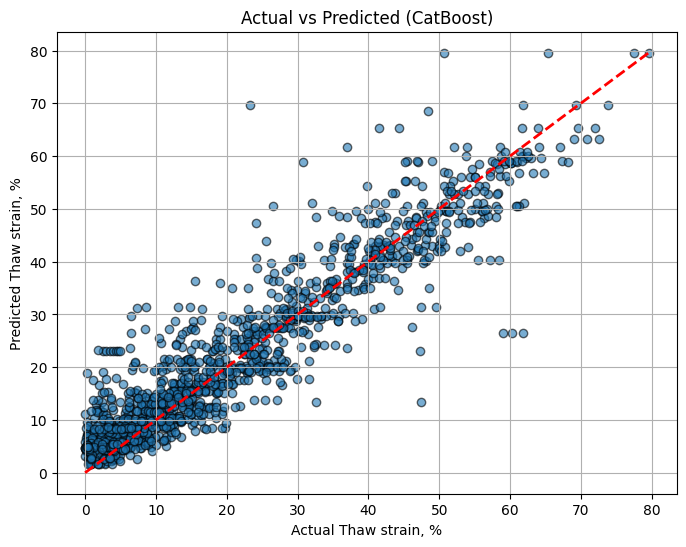

CatBoost (All Data) RMSE: 6.5565
CatBoost (All Data) R²: 0.8652


In [44]:
import matplotlib.pyplot as plt
import numpy as np
print(X, Y)
# ✅ Predict on test set
y_pred = cat.predict(X)

rmse = np.sqrt(mean_squared_error(Y, y_pred))
print(f"Final Test RMSE: {rmse:.4f}")



# ✅ Scatter plot: Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(Y, y_pred, alpha=0.6, edgecolor="k")
plt.plot([Y.min(), Y.max()],
         [Y.min(), Y.max()],
         "r--", lw=2)   # 45° reference line

plt.xlabel("Actual Thaw strain, %")
plt.ylabel("Predicted Thaw strain, %")
plt.title("Actual vs Predicted (CatBoost)")
plt.grid(True)
plt.show()

from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# ✅ Predict over the entire dataset
y_pred_cat_all = cat.predict(X)

# ✅ Metrics
rmse_cat_all = np.sqrt(mean_squared_error(Y, y_pred_cat_all))
r2_cat_all = r2_score(Y, y_pred_cat_all)

print(f"CatBoost (All Data) RMSE: {rmse_cat_all:.4f}")
print(f"CatBoost (All Data) R²: {r2_cat_all:.4f}")

